# Etapa 5 — Descriptores de textura (GLCM + LBP) y decisión tiña / no tiña
**PSIB 2026 Q2 — Grupo 9 (Del Carril, Escobar, Uthurralt)**

Objetivo: con las imágenes ya procesadas por la interfaz hasta la **Etapa 4**, ver qué descriptores de textura separan mejor la tiña de las otras lesiones y dejar armada la regla que usa la interfaz (`etapas/e6_clasificacion.py`).

Módulos que se usan:

| Módulo | Qué calcula |
|---|---|
| `e5_descriptores.py` | GLCM sobre L\* (32 niveles, d = 1 y 2, 4 ángulos) **respetando la máscara** de cada zona → contraste, disimilitud, homogeneidad, energía, correlación, entropía |
| `e5_lbp.py` | LBP *uniform* (P = 8, R = 1) dentro de cada zona → histograma de los 10 códigos + entropía |
| `e6_clasificacion.py` | calcula esos descriptores para una imagen y aplica la regla guardada en `resultados/Etapa_5/clasificador.json` |

Recorrido:
1. Carga de lo que exporta la interfaz al terminar la Etapa 4 (`resultados/Etapa_4/e4_*.npz`: L\* + máscaras `lesion`, `borde`, `centro`, `perilesional`).
2. Paso a paso sobre dos casos de ejemplo (una tiña y una no tiña): zonas, GLCM por zona, mapas locales de textura, LBP.
3. Cálculo de los descriptores para todas las imágenes → `resultados/Etapa_5/descriptores_lbp.csv` y `descriptores_texturales.csv`.
4. Qué descriptores separan mejor TC de Otras.
5. Elección de los descriptores y sus umbrales → `resultados/Etapa_5/clasificador.json`.
6. Prueba de `e6_clasificacion.clasificar()` sobre todas las imágenes (lo mismo que va a hacer la interfaz).

Todas las figuras se guardan en `resultados/Etapa_5/figuras/` para el informe.

## 0. Configuración

**Datos**: solo los archivos que genera la interfaz al pasar la Etapa 4 (`exportar_e4` → `resultados/Etapa_4/e4_<nombre>.npz`). Cada uno trae L\*, el RGB y las zonas de la lesión tal como quedaron después de la ROI y de la edición de la máscara en la interfaz.

La clase sale del nombre del archivo:

| Nombre | Clase | Origen |
|---|---|---|
| `TC_01_PMC`, `TC_02_dermnet`, … | **TC** (tiña corporis) | imágenes externas |
| `CD (n)`, `EC (n)` | **Otras** (dermatitis de contacto, eczema) | dataset reducido |

Las TC del dataset (`TC (n)`) **no se usan**: si alguna quedó en `Etapa_4` se descarta (`EXCLUIR`). Cualquier archivo cuyo nombre no empiece con TC, CD o EC se clasifica igual pero no entra al entrenamiento.

In [1]:
%matplotlib inline
import sys
import re
import json
import time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from skimage.filters.rank import entropy as entropia_local
from skimage.morphology import disk

# El notebook vive en etapas/: la raíz del proyecto es la carpeta de arriba
ROOT = Path.cwd().parent if Path.cwd().name == "etapas" else Path.cwd()
sys.path.insert(0, str(ROOT))

from etapas import e5_descriptores as glcm
from etapas import e5_lbp as lbp
from etapas import e6_clasificacion as e6

RESULTADOS = ROOT / "resultados"
CARPETA_E5 = RESULTADOS / "Etapa_5"
CARPETA_FIG = CARPETA_E5 / "figuras"
CARPETA_FIG.mkdir(parents=True, exist_ok=True)

CARPETA_E4 = RESULTADOS / "Etapa_4"          # salida de la interfaz (exportar_e4)
EXCLUIR = re.compile(r"^TC \(\d+\)$")          # TC del dataset reducido: no se usan

EJEMPLO_TC = "TC_05_dermnet"   # casos de las figuras paso a paso (si no existen, se toma el primero de cada clase)
EJEMPLO_OTRAS = "EC (37)"

ZONAS = glcm.ZONAS          # ["lesion", "borde", "centro", "perilesional"]
DESC_GLCM = ["contrast", "dissimilarity", "homogeneity", "energy", "correlation", "entropy"]
DESC_LBP = [f"lbp_{i}" for i in range(lbp.P + 2)] + ["lbp_entropia"]

COLOR_CLASE = {"TC": "#c0392b", "Otras": "#2874a6"}
COLOR_ZONA = {"lesion": "#f1c40f", "borde": "#ff8c00", "centro": "#58d68d", "perilesional": "#5dade2"}

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.titlesize": 10})


def guardar(fig, nombre):
    ruta = CARPETA_FIG / f"{nombre}.png"
    fig.savefig(ruta, bbox_inches="tight")
    print(f"  figura guardada: {ruta.relative_to(ROOT)}")


print("Raíz del proyecto:", ROOT)

Raíz del proyecto: c:\Users\ronal\Documents\Q2 2026\PSIB\TP Imagenes\PSIB2026Q2-TPI-Grupo9-DelCarril-Ecobar-Uthurralt


## 1. Carga de los resultados de la Etapa 4 (interfaz)

Cada caso queda como un diccionario con `L` (L\* en 0–100, **sin filtrar**: la mediana de la Etapa 2 borraría justo la textura que se quiere medir), las cuatro máscaras de zona y la imagen RGB para las figuras.

In [2]:
def clase_desde_nombre(nombre):
    m = re.match(r"(?:roi_)?\s*([A-Za-z]+)", nombre)
    subtipo = m.group(1).upper() if m else ""
    if subtipo == "TC":
        return subtipo, "TC"
    if subtipo in ("CD", "EC"):
        return subtipo, "Otras"
    return subtipo, None


def cargar_etapa4(carpeta=CARPETA_E4, patron="e4_*.npz"):
    casos, excluidos = [], []
    for ruta in sorted(carpeta.glob(patron)):
        id_ = ruta.stem[len("e4_"):]
        if EXCLUIR.match(id_):
            excluidos.append(id_)
            continue
        with np.load(ruta) as d:
            caso = {"id": id_, "L": d["L"].astype(np.float32), "rgb": d["rgb"] if "rgb" in d.files else None}
            caso.update({z: d[z].astype(bool) for z in ZONAS})
        caso["subtipo"], caso["clase"] = clase_desde_nombre(id_)
        caso["fuente"] = "externa" if caso["clase"] == "TC" else "dataset"
        casos.append(caso)
    return casos, excluidos


casos, excluidos = cargar_etapa4()
CASOS = {c["id"]: c for c in casos}

resumen = pd.DataFrame([{"id": c["id"], "subtipo": c["subtipo"], "clase": c["clase"],
                         **{f"px_{z}": int(c[z].sum()) for z in ZONAS}} for c in casos]).set_index("id")
print(f"Archivos leídos de {CARPETA_E4.relative_to(ROOT)}: {len(casos)}")
if excluidos:
    print(f"Descartados (TC del dataset): {excluidos}")
display(pd.crosstab(resumen["subtipo"], resumen["clase"].fillna("sin etiqueta"), margins=True))
sin_borde = resumen.index[resumen["px_borde"] == 0].tolist()
if sin_borde:
    print("Lesiones difusas (sin borde ni perilesional):", sin_borde)

n_tc, n_otras = (resumen["clase"] == "TC").sum(), (resumen["clase"] == "Otras").sum()
if n_tc < 3 or n_otras < 3:
    raise RuntimeError(
        f"Hay {n_tc} TC y {n_otras} Otras en {CARPETA_E4}. Para entrenar hacen falta las dos clases: "
        "pasá por la interfaz (hasta la Etapa 4) las imágenes CD y EC del dataset y las TC externas.")

# Casos de ejemplo para las figuras
if EJEMPLO_TC not in CASOS:
    EJEMPLO_TC = resumen.index[resumen["clase"] == "TC"][0]
if EJEMPLO_OTRAS not in CASOS:
    EJEMPLO_OTRAS = resumen.index[resumen["clase"] == "Otras"][0]
print(f"Ejemplos para las figuras: {EJEMPLO_TC} (TC) y {EJEMPLO_OTRAS} (Otras)")

Archivos leídos de resultados\Etapa_4: 28


clase,Otras,TC,All
subtipo,,,
CD,9,0,9
EC,9,0,9
TC,0,10,10
All,18,10,28


Ejemplos para las figuras: TC_05_dermnet (TC) y EC (37) (Otras)


## 2. Paso a paso sobre dos casos de ejemplo

### 2.1 Zonas de la Etapa 4
`borde` = lesión − erosión (anillo activo), `centro` = lesión erosionada, `perilesional` = dilatación − lesión (piel sana de referencia de la misma foto).

  figura guardada: resultados\Etapa_5\figuras\fig01_zonas_ejemplos.png


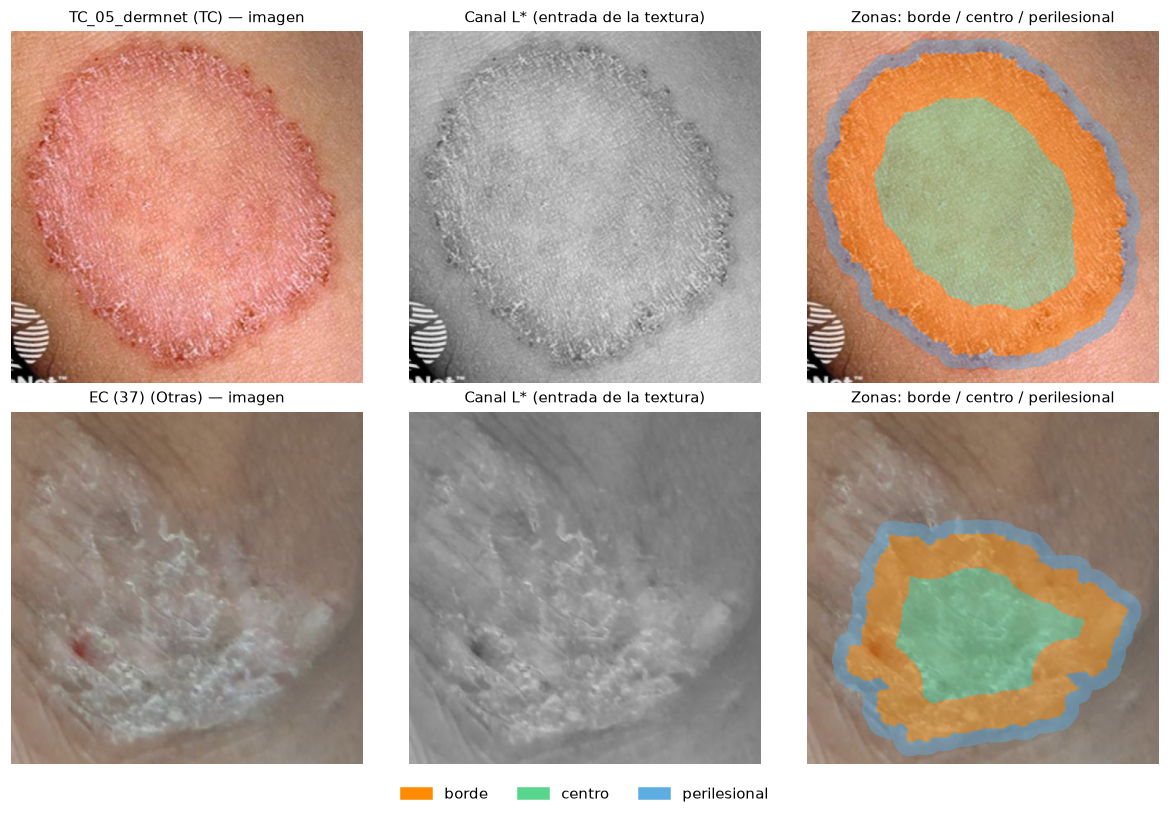

In [3]:
def fondo(caso):
    # RGB si está disponible; si no, L* en gris
    if caso.get("rgb") is not None:
        return caso["rgb"], None
    return caso["L"], dict(cmap="gray", vmin=0, vmax=100)


def superponer_zonas(caso, alfa=0.45):
    base = caso["rgb"] if caso.get("rgb") is not None else np.repeat(
        (np.clip(caso["L"], 0, 100) * 2.55).astype(np.uint8)[..., None], 3, axis=2)
    salida = base.astype(float).copy()
    for z in ["perilesional", "borde", "centro"]:
        color = np.array([int(COLOR_ZONA[z][i:i + 2], 16) for i in (1, 3, 5)], dtype=float)
        salida[caso[z]] = (1 - alfa) * salida[caso[z]] + alfa * color
    return salida.astype(np.uint8)


def contornos(ax, caso, zonas=("borde", "centro"), lw=1.0):
    for z in zonas:
        if caso[z].any():
            ax.contour(caso[z].astype(float), levels=[0.5], colors=[COLOR_ZONA[z]], linewidths=lw)


ejemplos = [CASOS[EJEMPLO_TC], CASOS[EJEMPLO_OTRAS]]

fig, axs = plt.subplots(2, 3, figsize=(11, 7.4))
for fila, caso in enumerate(ejemplos):
    img, kw = fondo(caso)
    axs[fila, 0].imshow(img, **(kw or {}))
    axs[fila, 0].set_title(f"{caso['id']} ({caso['clase']}) — imagen")
    axs[fila, 1].imshow(caso["L"], cmap="gray", vmin=0, vmax=100)
    axs[fila, 1].set_title("Canal L* (entrada de la textura)")
    axs[fila, 2].imshow(superponer_zonas(caso))
    axs[fila, 2].set_title("Zonas: borde / centro / perilesional")
for ax in axs.ravel():
    ax.axis("off")
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=COLOR_ZONA[z], label=z) for z in ["borde", "centro", "perilesional"]],
           loc="lower center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0.04, 1, 1))
guardar(fig, "fig01_zonas_ejemplos")
plt.show()

### 2.2 GLCM por zona (`e5_descriptores.py`)

1. **Cuantización** (`cuantizar_L`): L\* (0–100) → 32 niveles. Con 256 niveles la matriz de 256×256 quedaría casi vacía.
2. **GLCM enmascarada** (`glcm_enmascarada`): para un desplazamiento (d, θ) se cuentan los pares (i, j) de niveles **con los dos píxeles dentro de la zona**, se simetriza y se normaliza → P(i, j).
3. **Descriptores** (`calcular_descriptores`): se calculan para d ∈ {1, 2} y θ ∈ {0°, 45°, 90°, 135°} y se promedian:

$$\text{CON} = \sum_{i,j}(i-j)^2 P(i,j) \qquad \text{HOM} = \sum_{i,j}\frac{P(i,j)}{1+(i-j)^2} \qquad \text{ENE} = \sum_{i,j}P(i,j)^2 \qquad \text{ENT} = -\sum_{i,j}P(i,j)\log_2 P(i,j)$$

Una textura **lisa** concentra P cerca de la diagonal (i ≈ j): contraste bajo, homogeneidad y energía altas. Una textura **rugosa o descamada** dispersa P fuera de la diagonal: contraste y entropía altos.

Abajo: la GLCM promedio (d = 1, 4 ángulos) de cada zona, en escala logarítmica.

  figura guardada: resultados\Etapa_5\figuras\fig02_glcm_por_zona.png


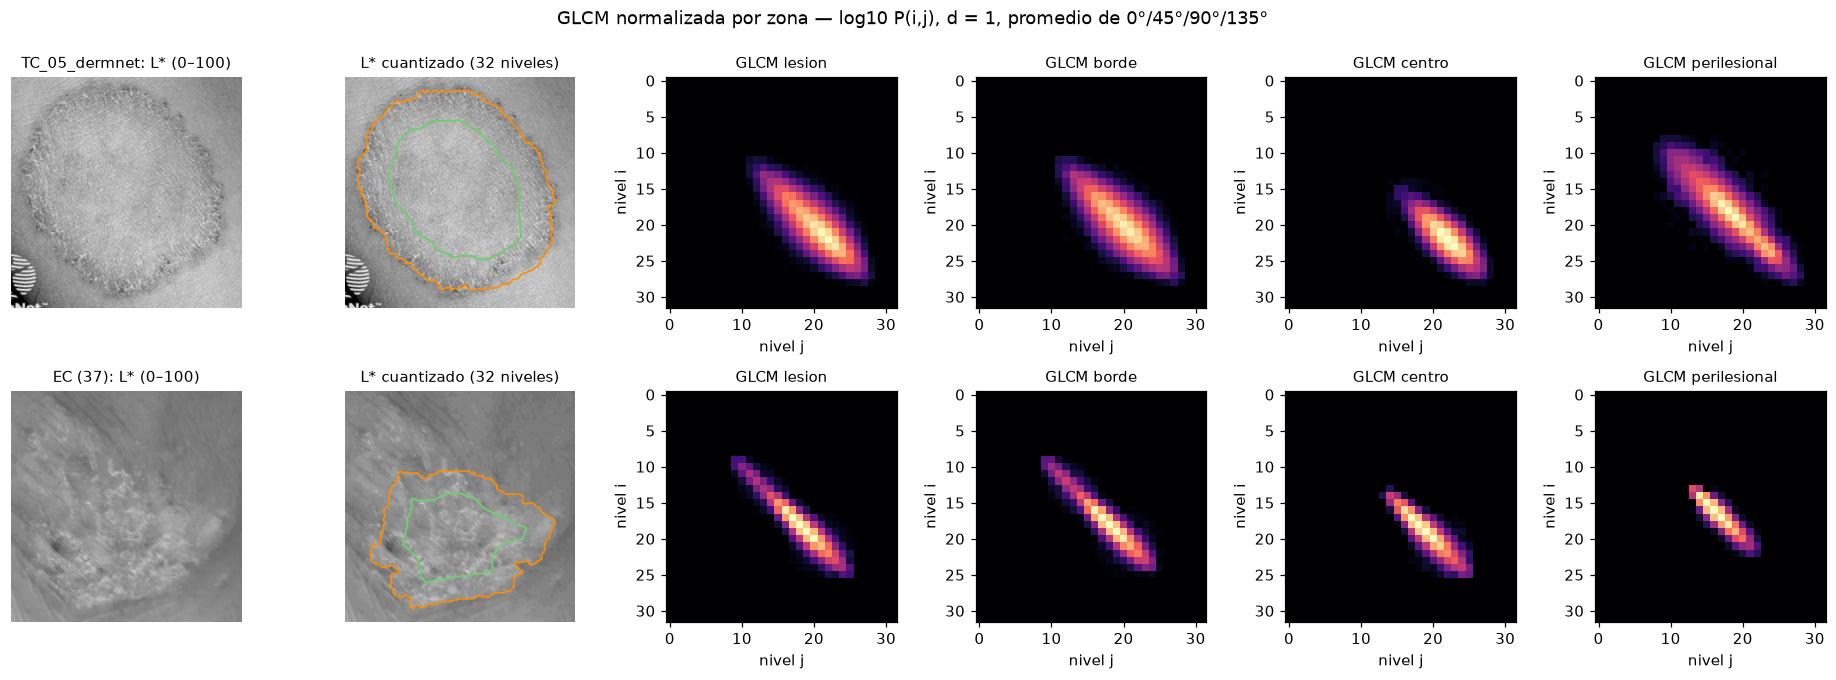

contrast  dissimilarity  homogeneity  energy  \
caso          zona                                                         
TC_05_dermnet lesion           1.561          0.873        0.629   0.195   
              borde            1.966          0.995        0.592   0.177   
              centro           1.092          0.730        0.671   0.248   
              perilesional     1.194          0.713        0.688   0.201   
EC (37)       lesion           0.390          0.337        0.837   0.315   
              borde            0.366          0.319        0.845   0.325   
              centro           0.423          0.361        0.826   0.305   
              perilesional     0.239          0.223        0.890   0.393   

                            correlation  entropy  
caso          zona                                
TC_05_dermnet lesion              0.825    5.312  
              borde               0.795    5.554  
              centro              0.738    4.538  
              perilesional        0.906    5.303  
EC (37)       lesion              0.926    3.982  
              borde               0.930    3.925  
              centro              0.915    4.011  
              perilesional        0.926    3.324

In [4]:
fig, axs = plt.subplots(2, 6, figsize=(17, 6), gridspec_kw={"width_ratios": [1.1, 1.1, 1, 1, 1, 1]})
filas_tabla = []
for fila, caso in enumerate(ejemplos):
    Lq = glcm.cuantizar_L(caso["L"])
    axs[fila, 0].imshow(caso["L"], cmap="gray", vmin=0, vmax=100)
    axs[fila, 0].set_title(f"{caso['id']}: L* (0–100)")
    axs[fila, 1].imshow(Lq, cmap="gray", vmin=0, vmax=glcm.NIVELES - 1)
    axs[fila, 1].set_title(f"L* cuantizado ({glcm.NIVELES} niveles)")
    contornos(axs[fila, 1], caso)
    for col, zona in enumerate(ZONAS, start=2):
        P = glcm.glcm_promedio(caso["L"], caso[zona], distancia=1)
        ax = axs[fila, col]
        if P is None:
            ax.text(0.5, 0.5, "zona vacía", ha="center", va="center"); ax.set_axis_off(); continue
        ax.imshow(np.log10(P + 1e-5), cmap="magma", vmin=-5, vmax=-1, origin="upper")
        ax.set_title(f"GLCM {zona}")
        ax.set_xlabel("nivel j"); ax.set_ylabel("nivel i")
        d = glcm.calcular_descriptores(caso["L"], caso[zona]) or {}
        filas_tabla.append({"caso": caso["id"], "zona": zona, **{k: d.get(k) for k in DESC_GLCM}})
    axs[fila, 0].axis("off"); axs[fila, 1].axis("off")
fig.suptitle("GLCM normalizada por zona — log10 P(i,j), d = 1, promedio de 0°/45°/90°/135°", y=1.0)
fig.tight_layout(h_pad=3)
guardar(fig, "fig02_glcm_por_zona")
plt.show()

display(pd.DataFrame(filas_tabla).set_index(["caso", "zona"]).round(3))

### 2.3 Mapas locales de textura GLCM

Para *ver* dónde está la textura, se calculan los mismos descriptores en una ventana deslizante (`mapas_glcm_locales`: ventana de 15×15 px, d = 1; `mapa_entropia_glcm`: ventana de 21×21 cada 6 px). No se usan para decidir: son solo para interpretar y para el informe. Contornos: borde (naranja) y centro (verde).

Mapas calculados en 5.3 s
  figura guardada: resultados\Etapa_5\figuras\fig03_mapas_glcm_locales.png


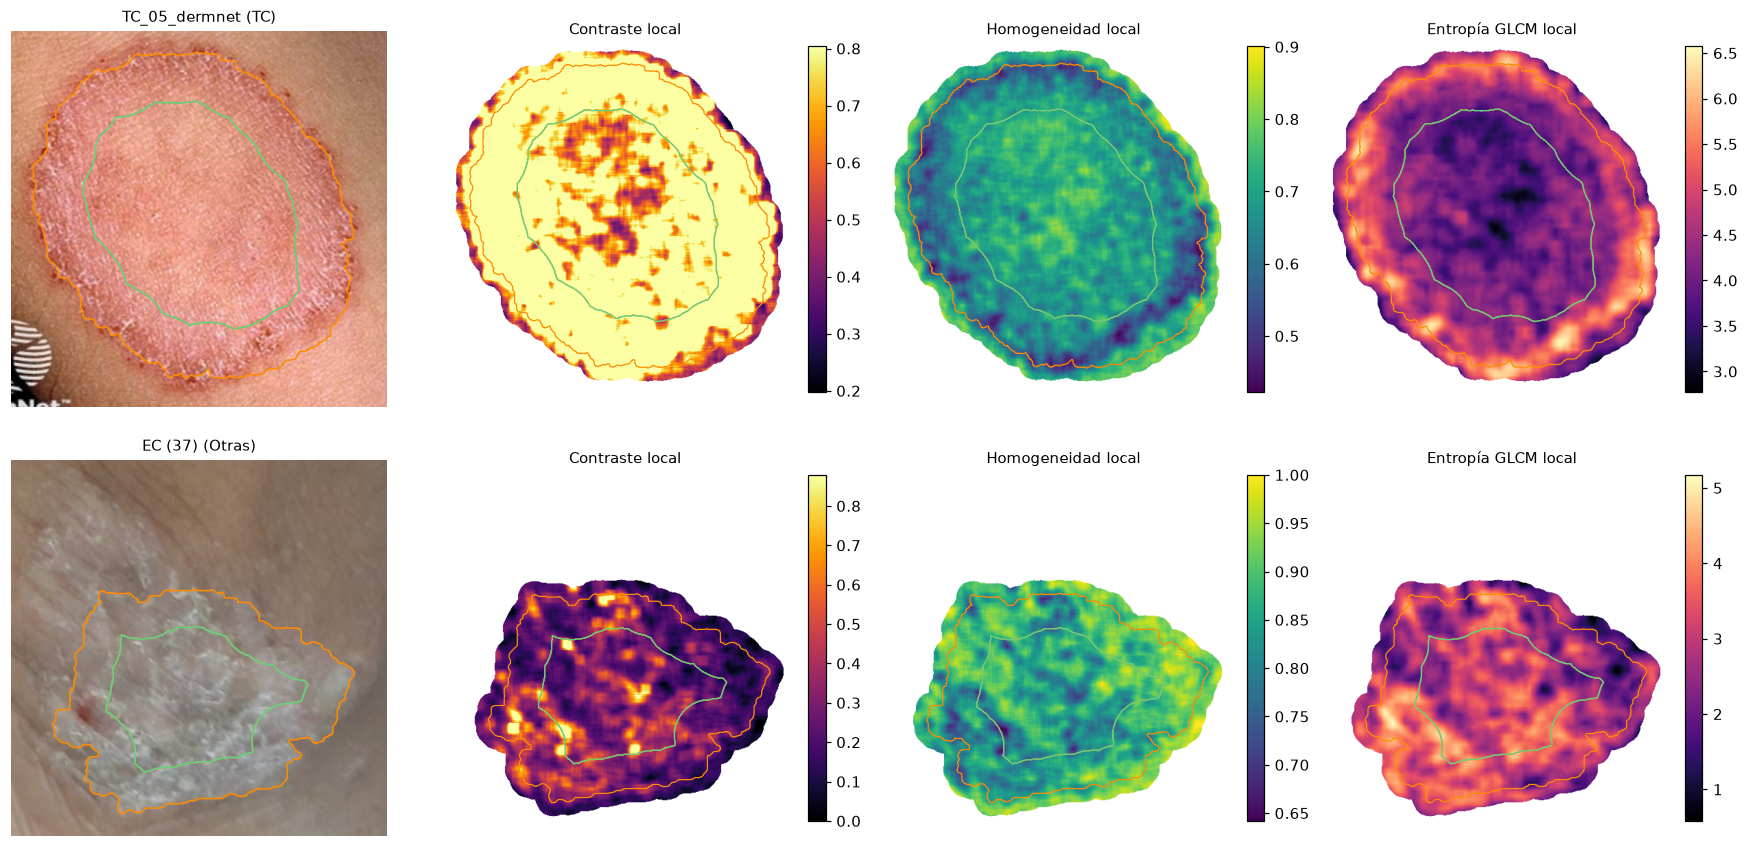

In [5]:
t0 = time.time()
mapas = {}
for caso in ejemplos:
    m = glcm.mapas_glcm_locales(caso["L"], ventana=15, distancia=1)
    m["entropy"] = glcm.mapa_entropia_glcm(caso["L"], ventana=21, paso=6)
    mapas[caso["id"]] = m
print(f"Mapas calculados en {time.time() - t0:.1f} s")

columnas = [("contrast", "Contraste local", "inferno"), ("homogeneity", "Homogeneidad local", "viridis"),
            ("entropy", "Entropía GLCM local", "magma")]
fig, axs = plt.subplots(2, 4, figsize=(16, 8))
for fila, caso in enumerate(ejemplos):
    img, kw = fondo(caso)
    axs[fila, 0].imshow(img, **(kw or {}))
    axs[fila, 0].set_title(f"{caso['id']} ({caso['clase']})")
    contornos(axs[fila, 0], caso)
    fuera = ~(caso["lesion"] | caso["perilesional"])
    for col, (clave, titulo, cmap) in enumerate(columnas, start=1):
        mapa = np.ma.masked_where(fuera, mapas[caso["id"]][clave])
        vmax = np.percentile(mapas[EJEMPLO_OTRAS][clave][~fuera], 99) if clave == "contrast" else None
        im = axs[fila, col].imshow(mapa, cmap=cmap, vmax=vmax)
        contornos(axs[fila, col], caso, lw=0.8)
        axs[fila, col].set_title(titulo)
        fig.colorbar(im, ax=axs[fila, col], fraction=0.046, pad=0.02)
for ax in axs.ravel():
    ax.axis("off")
fig.tight_layout()
guardar(fig, "fig03_mapas_glcm_locales")
plt.show()

### 2.4 LBP (`e5_lbp.py`)

Cada píxel se compara con sus 8 vecinos a radio 1 (vecino ≥ centro → 1). Con el método *uniform* el patrón se resume en un código:

| Código | Patrón | Interpretación |
|---|---|---|
| 0 | ningún vecino ≥ centro | punto **claro** aislado (el centro es el máximo) |
| 1–3 | pocos vecinos ≥ centro | esquina / borde convexo claro |
| 4 | mitad y mitad | **borde** recto (escalón de intensidad) |
| 5–7 | muchos vecinos ≥ centro | esquina / borde cóncavo oscuro |
| 8 | todos ≥ centro | punto **oscuro** o zona **plana** |
| 9 | no uniforme | ruido / textura desordenada |

`calcular_lbp` erosiona la máscara 3×3 (para que el vecindario no salga de la zona) y devuelve el histograma normalizado de los 10 códigos más su entropía.

  figura guardada: resultados\Etapa_5\figuras\fig04_lbp_ejemplos.png


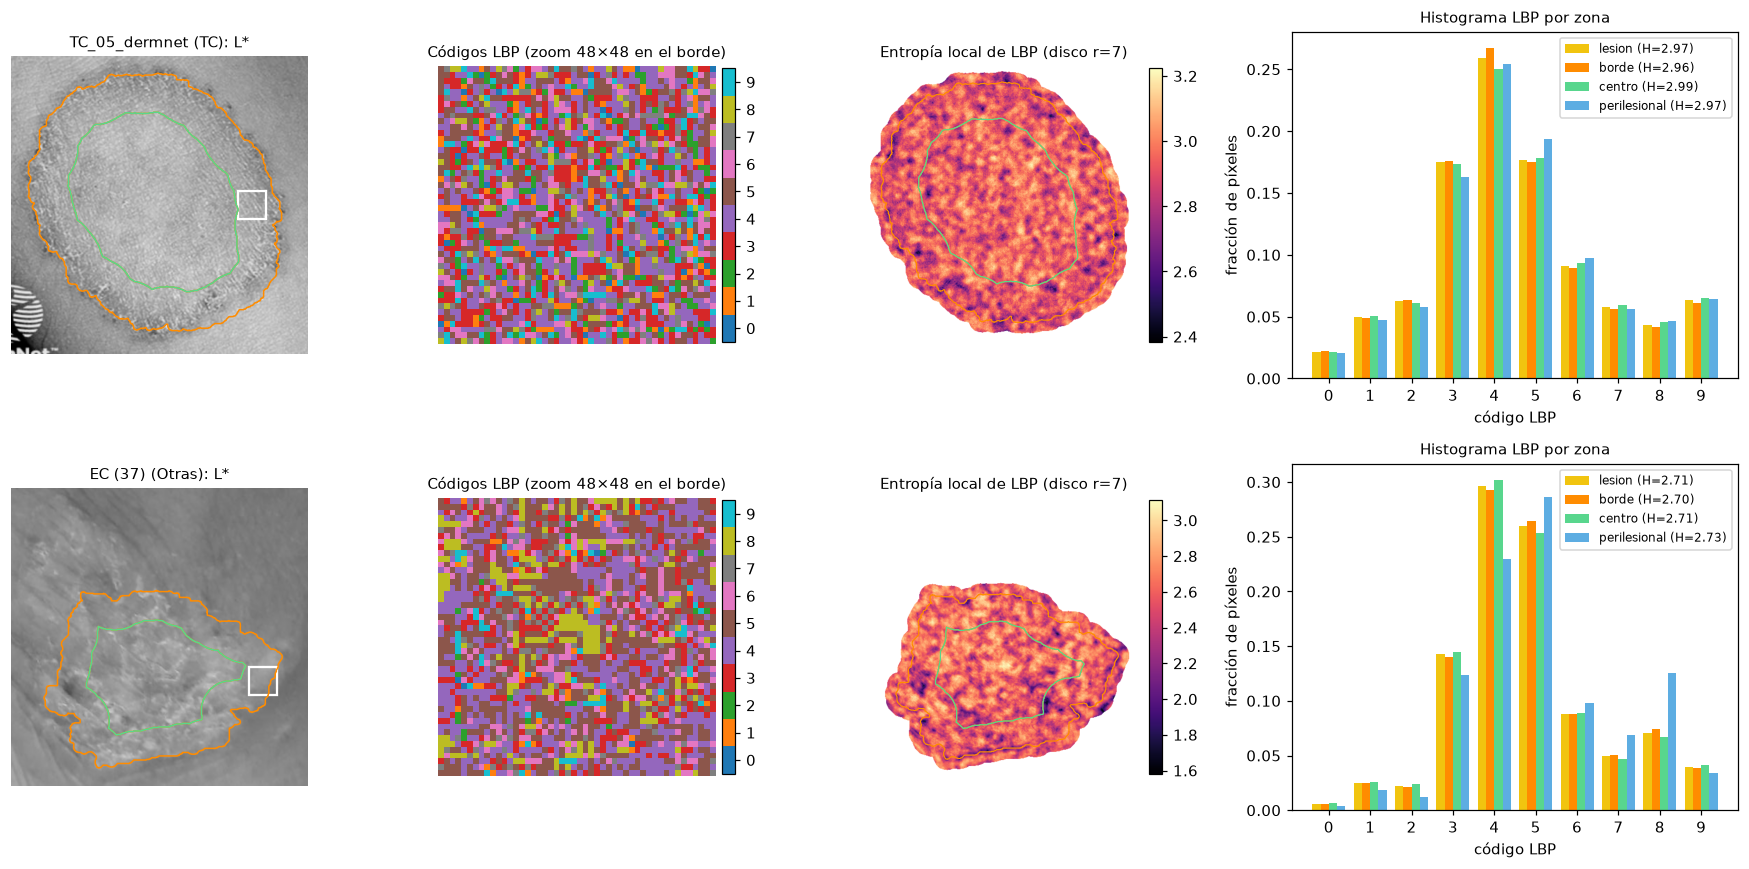

In [6]:
cmap_lbp = ListedColormap(plt.get_cmap("tab10").colors)
fig = plt.figure(figsize=(16, 8))
grilla = fig.add_gridspec(2, 4, width_ratios=[1, 1, 1, 1.5])
for fila, caso in enumerate(ejemplos):
    codigos = lbp.imagen_lbp(caso["L"])
    ent = entropia_local(codigos.astype(np.uint8), disk(7))
    fuera = ~(caso["lesion"] | caso["perilesional"])

    ax = fig.add_subplot(grilla[fila, 0]); ax.imshow(caso["L"], cmap="gray", vmin=0, vmax=100)
    contornos(ax, caso); ax.set_title(f"{caso['id']} ({caso['clase']}): L*"); ax.axis("off")

    ax = fig.add_subplot(grilla[fila, 1])
    # recorte de 48x48 centrado en un punto del borde (marcado en blanco en la imagen de la izquierda)
    rr, cc = np.nonzero(caso["borde"] if caso["borde"].any() else caso["lesion"])
    r0 = int(np.clip(rr[len(rr) // 2] - 24, 0, caso["L"].shape[0] - 48))
    c0 = int(np.clip(cc[len(cc) // 2] - 24, 0, caso["L"].shape[1] - 48))
    fig.axes[-2].add_patch(plt.Rectangle((c0, r0), 48, 48, fill=False, ec="white", lw=1.5))
    im = ax.imshow(codigos[r0:r0 + 48, c0:c0 + 48], cmap=cmap_lbp, vmin=-0.5, vmax=9.5, interpolation="nearest")
    ax.set_title("Códigos LBP (zoom 48×48 en el borde)"); ax.axis("off")
    fig.colorbar(im, ax=ax, ticks=range(10), fraction=0.046, pad=0.02)

    ax = fig.add_subplot(grilla[fila, 2])
    im = ax.imshow(np.ma.masked_where(fuera, ent), cmap="magma")
    contornos(ax, caso, lw=0.8); ax.set_title("Entropía local de LBP (disco r=7)"); ax.axis("off")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)

    ax = fig.add_subplot(grilla[fila, 3])
    ancho = 0.2
    for k, zona in enumerate(ZONAS):
        r = lbp.calcular_lbp(caso["L"], caso[zona])
        if r is None:
            continue
        h = [r[f"lbp_{i}"] for i in range(10)]
        ax.bar(np.arange(10) + (k - 1.5) * ancho, h, width=ancho, color=COLOR_ZONA[zona],
               label=f"{zona} (H={r['lbp_entropia']:.2f})")
    ax.set_xticks(range(10)); ax.set_xlabel("código LBP"); ax.set_ylabel("fracción de píxeles")
    ax.set_title("Histograma LBP por zona"); ax.legend(fontsize=8)
fig.tight_layout()
guardar(fig, "fig04_lbp_ejemplos")
plt.show()

## 3. Descriptores de todas las imágenes

Para cada imagen y cada zona se calculan GLCM (`e5_descriptores`) y LBP (`e5_lbp`) con `e6.descriptores_por_zona`, que es la misma función que usa la interfaz. Se guardan en `resultados/Etapa_5/`:

* `descriptores_lbp.csv` y `descriptores_texturales.csv` (GLCM): una fila por imagen × zona.
* `tabla_descriptores.csv`: una fila por imagen, con los descriptores por zona y los **relativos**:
  * `dif_BC__X = X(borde) − X(centro)`: en la tiña el borde activo (descamado) tiene que ser distinto del centro, que tiende a aclararse.
  * `dif_LP__X = X(lesión) − X(perilesional)`: la lesión comparada con la piel sana de la misma foto.

Los relativos comparan zonas **de la misma foto**, así que dependen menos de la cámara y la iluminación. Esto importa porque todas las TC son externas y todas las Otras son del dataset: un descriptor por zona puede separar las clases solo porque las fotos vienen de fuentes distintas.

In [7]:
filas_glcm, filas_lbp, filas_ancha = [], [], []
t_total = time.time()
for n, caso in enumerate(casos, start=1):
    t0 = time.time()
    por_zona = e6.descriptores_por_zona(caso["L"], caso)
    for zona in ZONAS:
        base = {"imagen": caso["id"], "zona": zona, "clase": caso["clase"]}
        filas_glcm.append({**base, **{d: por_zona[zona][f"glcm_{d}"] for d in DESC_GLCM}})
        filas_lbp.append({**base, **{d: por_zona[zona][d] for d in DESC_LBP}})
    filas_ancha.append({"imagen": caso["id"], "clase": caso["clase"], **e6.descriptores_imagen(caso["L"], caso)})
    print(f"[{n:2d}/{len(casos)}] {caso['id']:<16} {str(caso['clase']):<6} {time.time() - t0:5.2f} s")
print(f"Total: {time.time() - t_total:.1f} s")

pd.DataFrame(filas_glcm).to_csv(CARPETA_E5 / "descriptores_texturales.csv", index=False)
pd.DataFrame(filas_lbp).to_csv(CARPETA_E5 / "descriptores_lbp.csv", index=False)
tabla = pd.DataFrame(filas_ancha).set_index("imagen")
tabla.to_csv(CARPETA_E5 / "tabla_descriptores.csv")
with open(CARPETA_E5 / "configuracion.json", "w", encoding="utf-8") as f:
    json.dump({"canal": "L*", "zonas": ZONAS,
               "glcm": {"niveles": glcm.NIVELES, "distancias": glcm.DISTANCIAS, "angulos_grados": glcm.ANGULOS,
                        "simetrica": True, "min_pixeles": glcm.MIN_PIXELES},
               "lbp": {"P": lbp.P, "R": lbp.R, "metodo": lbp.METODO}}, f, indent=4, ensure_ascii=False)

POR_ZONA = [c for c in tabla.columns if "__" in c and not c.startswith("dif_")]
RELATIVOS = [c for c in tabla.columns if c.startswith("dif_")]
entren = tabla[tabla["clase"].notna()]
y = (entren["clase"] == "TC").to_numpy().astype(int)
print(f"Guardados los CSV en {CARPETA_E5.relative_to(ROOT)} — {len(entren)} imágenes con clase "
      f"({y.sum()} TC, {(y == 0).sum()} Otras), {len(POR_ZONA)} descriptores por zona + {len(RELATIVOS)} relativos")

[ 1/28] CD (120)         Otras   0.92 s
[ 2/28] CD (126)         Otras   1.05 s
[ 3/28] CD (140)         Otras   0.89 s
[ 4/28] CD (161)         Otras   0.86 s
[ 5/28] CD (178)         Otras   0.84 s
[ 6/28] CD (188)         Otras   0.83 s
[ 7/28] CD (205)         Otras   0.83 s
[ 8/28] CD (217)         Otras   0.86 s
[ 9/28] CD (239)         Otras   0.84 s
[10/28] EC (22)          Otras   0.97 s
[11/28] EC (37)          Otras   0.85 s
[12/28] EC (371)         Otras   0.89 s
[13/28] EC (381)         Otras   0.85 s
[14/28] EC (385)         Otras   0.85 s
[15/28] EC (462)         Otras   0.83 s
[16/28] EC (58)          Otras   0.84 s
[17/28] EC (66)          Otras   0.85 s
[18/28] EC (78)          Otras   0.84 s
[19/28] TC_01_PMC        TC      0.96 s
[20/28] TC_02_dermnet    TC      0.90 s
[21/28] TC_03_GSA        TC      0.89 s
[22/28] TC_04_GSA        TC      0.89 s
[23/28] TC_05_dermnet    TC      0.90 s
[24/28] TC_06_ medico    TC      0.85 s
[25/28] TC_07_medico     TC      0.83 s


## 4. ¿Qué descriptores separan mejor tiña de no tiña?

Para cada descriptor se mide la **separación** con el AUC: se toman todos los pares (una TC, una Otras) y se cuenta en qué fracción la TC tiene el valor más alto.

* AUC = 1 → todas las TC están por encima de todas las Otras (separa perfecto, TC **mayor**).
* AUC = 0 → todas por debajo (separa perfecto, TC **menor**).
* AUC = 0.5 → no separa nada.

Por eso se ordena por |AUC − 0.5|: cuanto más lejos de 0.5, mejor separa (en cualquiera de los dos sentidos).

In [8]:
def auc(x, y):
    x = np.asarray(x, dtype=float); ok = ~np.isnan(x)
    a, b = x[ok & (y == 1)], x[ok & (y == 0)]
    if len(a) == 0 or len(b) == 0:
        return np.nan
    return (np.sum(a[:, None] > b[None, :]) + 0.5 * np.sum(a[:, None] == b[None, :])) / (len(a) * len(b))


ranking = pd.DataFrame({"descriptor": POR_ZONA + RELATIVOS})
ranking["tipo"] = np.where(ranking["descriptor"].str.startswith("dif_"), "relativo", "por zona")
ranking["media_TC"] = [entren.loc[entren.clase == "TC", d].mean() for d in ranking["descriptor"]]
ranking["media_Otras"] = [entren.loc[entren.clase == "Otras", d].mean() for d in ranking["descriptor"]]
ranking["AUC"] = [auc(entren[d].to_numpy(dtype=float), y) for d in ranking["descriptor"]]
ranking["separacion"] = (ranking["AUC"] - 0.5).abs()
ranking["en_TC_es"] = np.where(ranking["AUC"] > 0.5, "mayor", "menor")
ranking = ranking.sort_values("separacion", ascending=False).reset_index(drop=True)
ranking.to_csv(CARPETA_E5 / "ranking_descriptores.csv", index=False)
display(ranking.head(15).round(4))

,descriptor,tipo,media_TC,media_Otras,AUC,separacion,en_TC_es
0,dif_BC__lbp_9,relativo,-0.0026,0.0002,0.0778,0.4222,menor
1,dif_LP__glcm_contrast,relativo,0.2810,-0.0502,0.8278,0.3278,mayor
2,dif_LP__lbp_2,relativo,0.0037,0.0008,0.8222,0.3222,mayor
3,dif_LP__glcm_dissimilarity,relativo,0.0951,-0.0078,0.8111,0.3111,mayor
4,centro__lbp_2,por zona,0.0330,0.0083,0.7944,0.2944,mayor
5,lesion__lbp_2,por zona,0.0327,0.0082,0.7889,0.2889,mayor
6,dif_LP__lbp_3,relativo,0.0105,-0.0016,0.7833,0.2833,mayor
7,dif_LP__glcm_homogeneity,relativo,-0.0332,0.0004,0.2222,0.2778,menor
8,borde__lbp_2,por zona,0.0325,0.0081,0.7778,0.2778,mayor
9,centro__lbp_9,por zona,0.0543,0.0181,0.7556,0.2556,mayor


  figura guardada: resultados\Etapa_5\figuras\fig05_mapa_auc.png


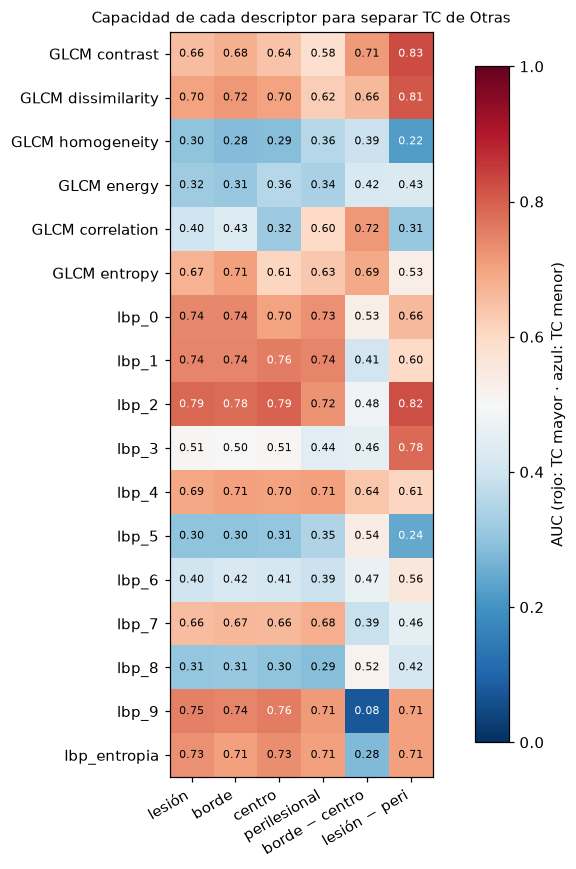

In [9]:
# Mapa de AUC: descriptor (filas) x zona / comparación (columnas)
nombres = e6.NOMBRES
cols = ZONAS + ["dif_BC", "dif_LP"]
matriz = np.array([[auc(entren[f"{z}__{d}"].to_numpy(dtype=float), y) for z in cols] for d in nombres])

fig, ax = plt.subplots(figsize=(8.5, 8))
im = ax.imshow(matriz, cmap="RdBu_r", vmin=0, vmax=1)
ax.set_xticks(range(len(cols)), ["lesión", "borde", "centro", "perilesional", "borde − centro", "lesión − peri"],
              rotation=30, ha="right")
ax.set_yticks(range(len(nombres)), [n.replace("glcm_", "GLCM ") for n in nombres])
for i in range(matriz.shape[0]):
    for j in range(matriz.shape[1]):
        v = matriz[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if abs(v - 0.5) > 0.25 else "black")
fig.colorbar(im, ax=ax, fraction=0.04, label="AUC (rojo: TC mayor · azul: TC menor)")
ax.set_title("Capacidad de cada descriptor para separar TC de Otras")
fig.tight_layout()
guardar(fig, "fig05_mapa_auc")
plt.show()

## 5. Elección de los descriptores y sus umbrales

Regla de votos, simple y fácil de explicar:

1. Se toman los `N_DESCRIPTORES` que más separan (por defecto solo **relativos**, por lo explicado en la sección 3). Si uno está muy correlacionado con otro ya elegido (|correlación| > `MAX_CORRELACION`) se saltea: mediría lo mismo dos veces.
2. A cada uno se le pone el **umbral** que más imágenes clasifica bien en el entrenamiento (máximo de sensibilidad + especificidad), con su sentido (TC mayor o menor que el umbral).
3. Para una imagen nueva, cada descriptor vota; si más de la mitad vota tiña → **tiña**.

La tabla de abajo muestra cuántas imágenes acierta la regla según cuántos descriptores se usen, para elegir `N_DESCRIPTORES`. Ojo: se mide sobre las mismas imágenes con las que se eligieron los umbrales, así que es optimista; la prueba real es con imágenes que no estén en `Etapa_4`.

In [10]:
N_DESCRIPTORES = 3        # conviene impar, para que no haya empates
SOLO_RELATIVOS = True
MAX_CORRELACION = 0.8


def mejor_umbral(x, y, sentido):
    # umbral (punto medio entre dos valores) que maximiza sensibilidad + especificidad
    v = np.sort(np.unique(x[~np.isnan(x)]))
    candidatos = (v[:-1] + v[1:]) / 2
    mejor, mejor_j = None, -1
    for u in candidatos:
        pred = x > u if sentido == "mayor" else x < u
        j = pred[y == 1].mean() + (~pred[y == 0]).mean()
        if j > mejor_j:
            mejor, mejor_j = u, j
    return float(mejor)


def elegir(n, solo_relativos=SOLO_RELATIVOS, max_corr=MAX_CORRELACION):
    candidatos = ranking[ranking["tipo"] == "relativo"] if solo_relativos else ranking
    elegidos = []
    for _, fila in candidatos.iterrows():
        d = fila["descriptor"]
        if any(abs(entren[d].corr(entren[e["descriptor"]], method="spearman")) > max_corr for e in elegidos):
            continue
        x = entren[d].to_numpy(dtype=float)
        elegidos.append({"descriptor": d, "sentido": fila["en_TC_es"], "umbral": mejor_umbral(x, y, fila["en_TC_es"]),
                         "AUC": round(float(fila["AUC"]), 3)})
        if len(elegidos) == n:
            break
    return elegidos


def aplicar(reglas, datos):
    votos = np.zeros(len(datos)); validos = np.zeros(len(datos))
    for r in reglas:
        x = datos[r["descriptor"]].to_numpy(dtype=float)
        ok = ~np.isnan(x)
        voto = (x > r["umbral"]) if r["sentido"] == "mayor" else (x < r["umbral"])
        votos += voto & ok; validos += ok
    return (votos > validos / 2).astype(int)


filas = []
for n in [1, 3, 5, 7]:
    pred = aplicar(elegir(n), entren)
    filas.append({"N_DESCRIPTORES": n, "aciertos": f"{(pred == y).sum()} de {len(y)}",
                  "TC reconocidas": f"{pred[y == 1].sum()} de {y.sum()}",
                  "Otras descartadas": f"{(pred[y == 0] == 0).sum()} de {(y == 0).sum()}"})
display(pd.DataFrame(filas).set_index("N_DESCRIPTORES"))

,aciertos,TC reconocidas,Otras descartadas
N_DESCRIPTORES,,,
1,24 de 28,10 de 10,14 de 18
3,25 de 28,10 de 10,15 de 18
5,24 de 28,10 de 10,14 de 18
7,25 de 28,10 de 10,15 de 18


,descriptor,sentido,umbral,AUC
0,dif_BC__lbp_9,menor,-0.000157,0.078
1,dif_LP__glcm_contrast,mayor,0.088846,0.828
2,dif_LP__lbp_2,mayor,0.000016,0.822


Guardado resultados\Etapa_5\clasificador.json
  figura guardada: resultados\Etapa_5\figuras\fig06_descriptores_elegidos.png


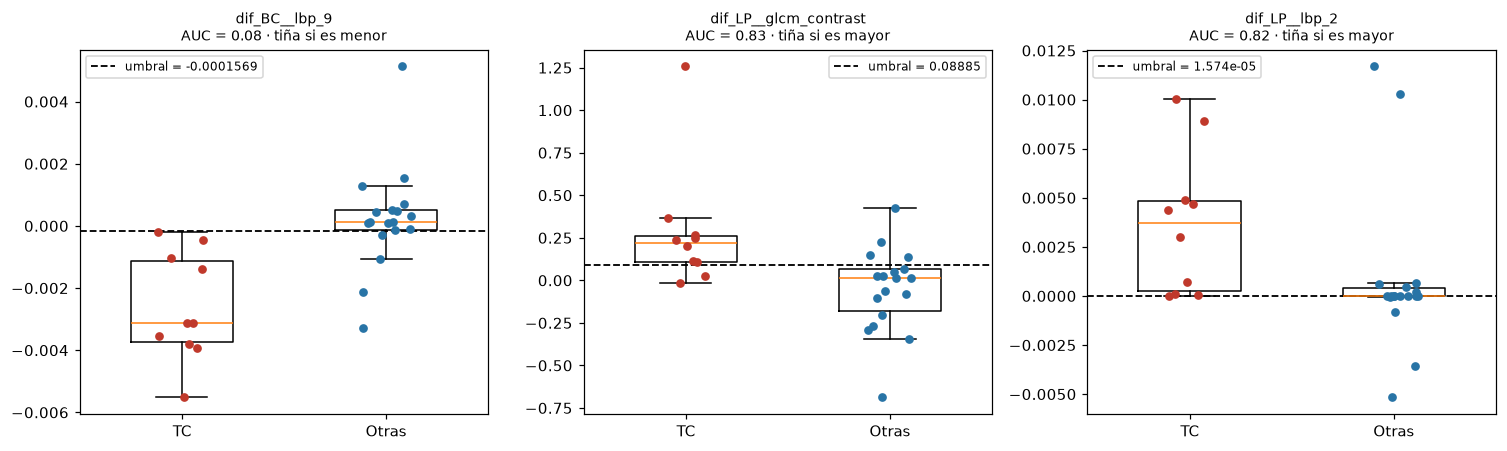

In [11]:
reglas = elegir(N_DESCRIPTORES)
display(pd.DataFrame(reglas))

clasificador = {"descriptores": reglas,
                "regla": "cada descriptor vota tiña si valor > umbral (sentido 'mayor') o valor < umbral ('menor'); "
                         "tiña si vota tiña más de la mitad",
                "entrenado_con": sorted(entren.index.tolist())}
with open(CARPETA_E5 / "clasificador.json", "w", encoding="utf-8") as f:
    json.dump(clasificador, f, indent=4, ensure_ascii=False)
print("Guardado", (CARPETA_E5 / "clasificador.json").relative_to(ROOT))

# Cada descriptor elegido con su umbral
fig, axs = plt.subplots(1, len(reglas), figsize=(4.6 * len(reglas), 4.2), squeeze=False)
rng = np.random.default_rng(0)
for ax, r in zip(axs[0], reglas):
    for k, clase in enumerate(["TC", "Otras"]):
        v = entren.loc[entren.clase == clase, r["descriptor"]].dropna().to_numpy()
        ax.boxplot([v], positions=[k], widths=0.5, showfliers=False)
        ax.scatter(k + rng.uniform(-0.12, 0.12, len(v)), v, s=22, color=COLOR_CLASE[clase], zorder=3)
    ax.axhline(r["umbral"], color="black", ls="--", lw=1.2, label=f"umbral = {r['umbral']:.4g}")
    ax.set_xticks([0, 1], ["TC", "Otras"])
    ax.set_title(f"{r['descriptor']}\nAUC = {r['AUC']:.2f} · tiña si es {r['sentido']}", fontsize=9)
    ax.legend(fontsize=8)
fig.tight_layout()
guardar(fig, "fig06_descriptores_elegidos")
plt.show()

## 6. Prueba de la función de la interfaz

Se clasifica cada imagen de `Etapa_4` con `e6_clasificacion.clasificar()`, que vuelve a calcular los descriptores desde L\* y las zonas y lee `clasificador.json`. Es exactamente lo que va a hacer la interfaz:

```python
from etapas.e6_clasificacion import clasificar
resultado = clasificar(res_e1["L"], res_e4)     # después de procesar_etapa4
resultado["veredicto"]                          # "tiña" / "no tiña"
```

In [12]:
filas = []
for caso in casos:
    r = e6.clasificar(caso["L"], caso)
    filas.append({"imagen": caso["id"], "clase": caso["clase"], "veredicto": r["veredicto"],
                  "votos tiña": f"{r['votos_tina']}/{r['validos']}",
                  "acierto": None if caso["clase"] is None else (r["veredicto"] == "tiña") == (caso["clase"] == "TC")})
res = pd.DataFrame(filas).set_index("imagen")
res.to_csv(CARPETA_E5 / "predicciones.csv")
print(f"Aciertos: {res['acierto'].sum()} de {res['acierto'].notna().sum()}")
display(pd.crosstab(res["clase"], res["veredicto"]))

Aciertos: 25 de 28


veredicto,no tiña,tiña
clase,,
Otras,15,3
TC,0,10


  figura guardada: resultados\Etapa_5\figuras\fig07_veredictos_TC.png


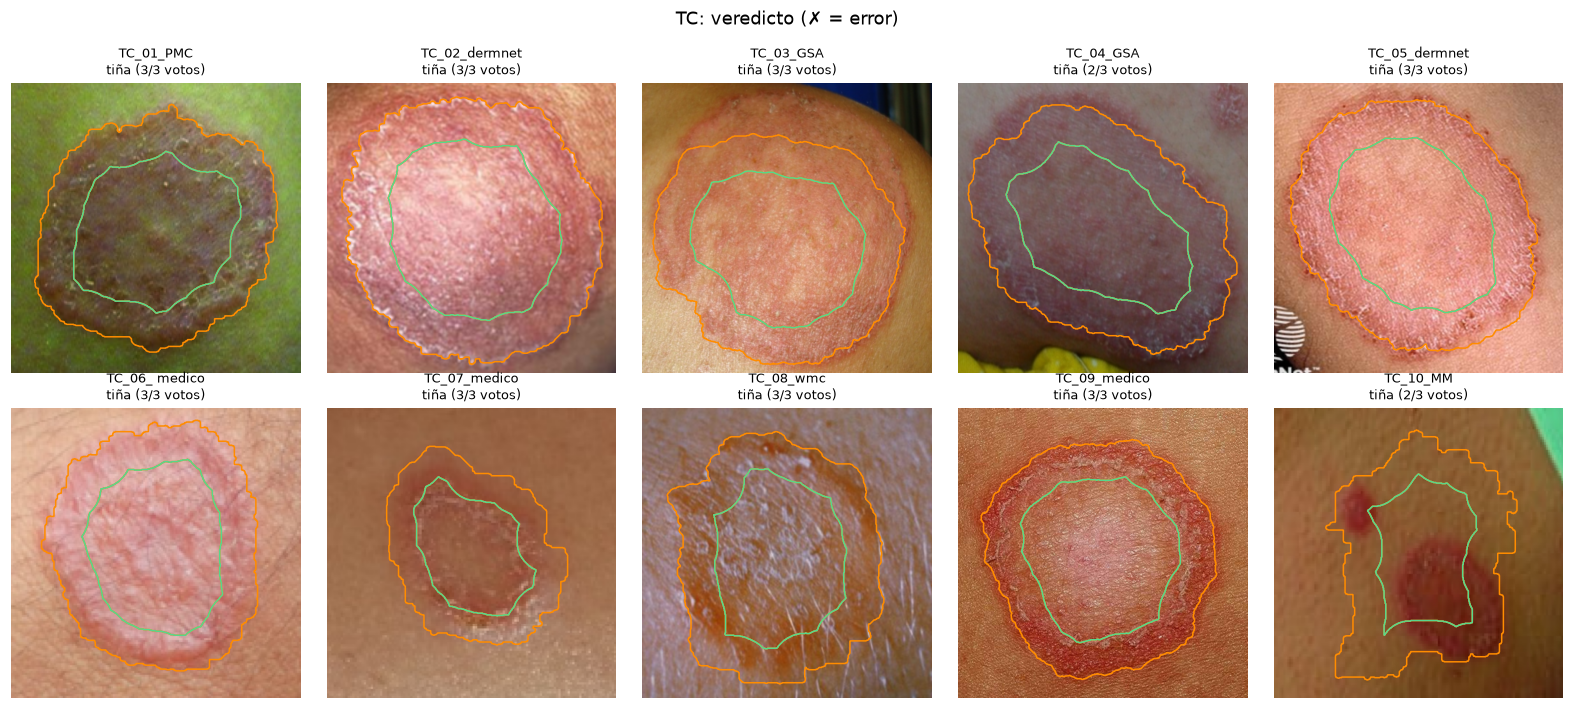

  figura guardada: resultados\Etapa_5\figuras\fig08_veredictos_otras.png


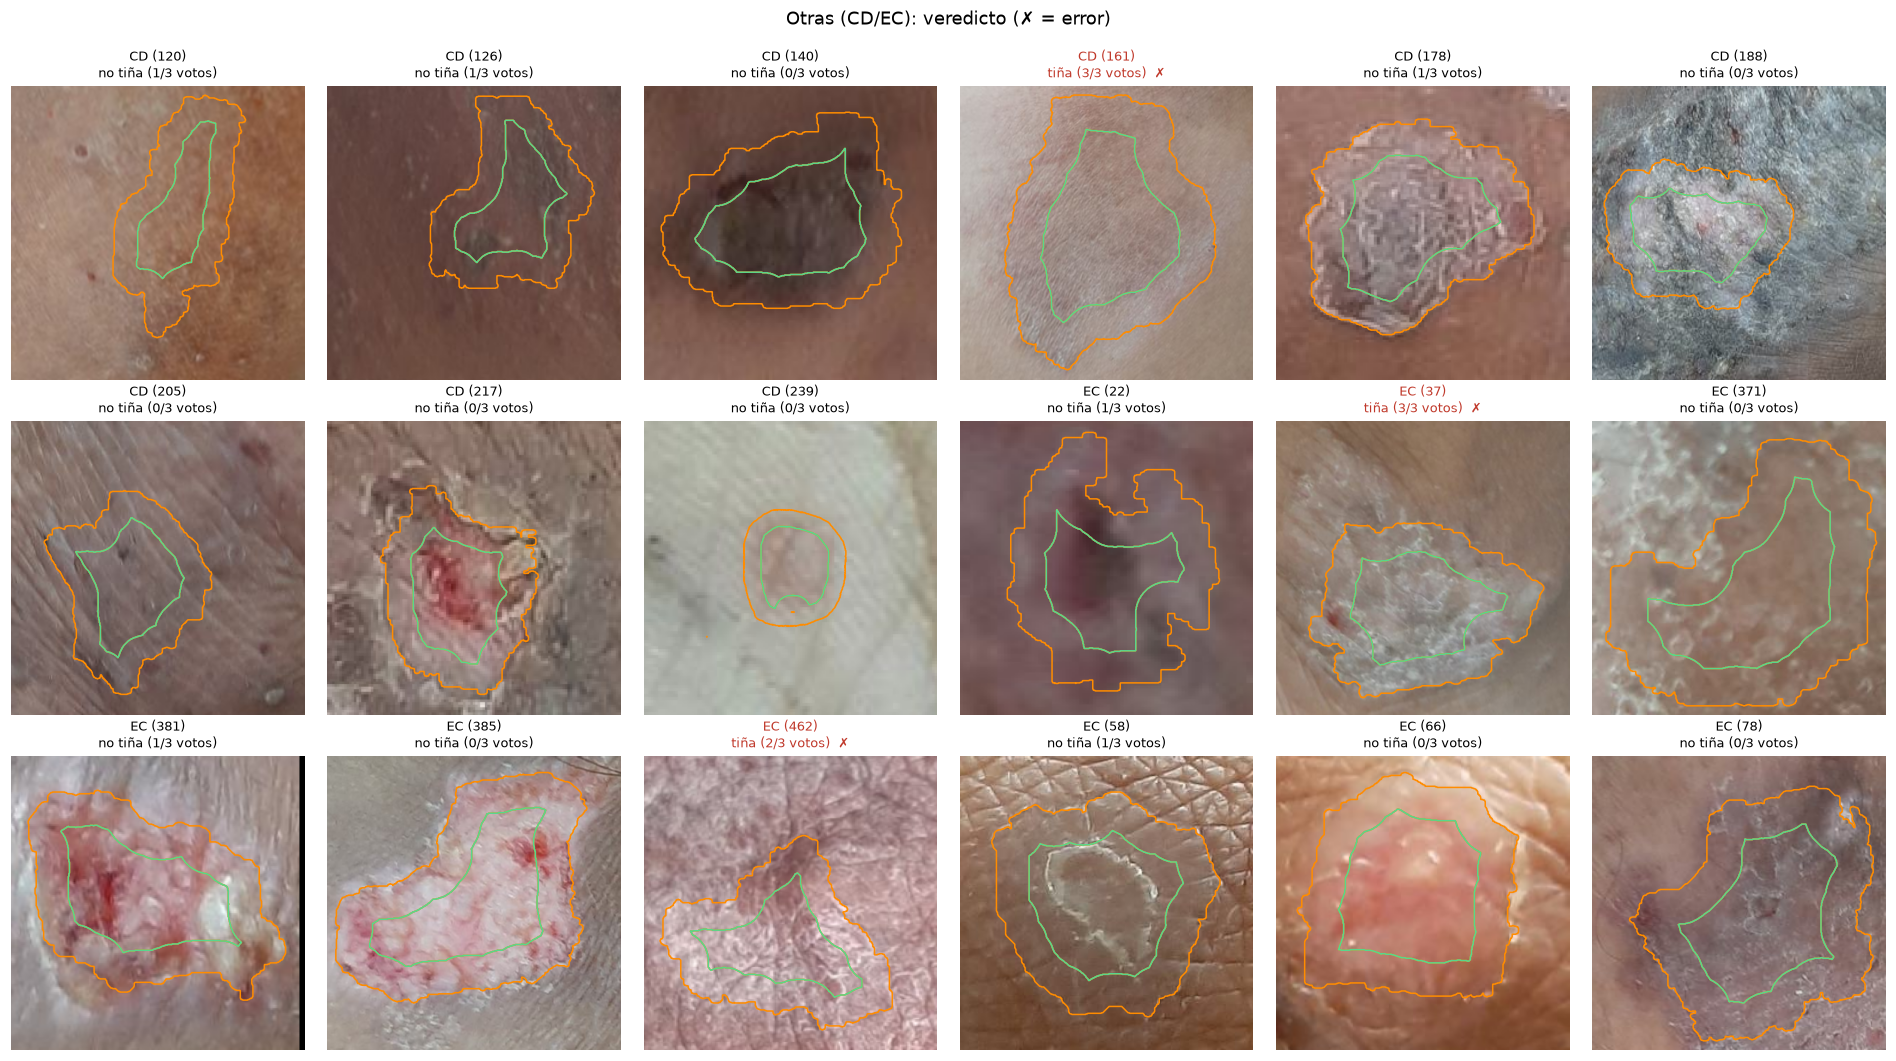

In [13]:
def grilla_veredictos(ids, titulo, nombre_fig, columnas=6):
    filas_ = int(np.ceil(len(ids) / columnas))
    fig, axs = plt.subplots(filas_, columnas, figsize=(2.9 * columnas, 3.2 * filas_), squeeze=False)
    for ax, id_ in zip(axs.ravel(), ids):
        caso = CASOS[id_]; r = res.loc[id_]
        img, kw = fondo(caso)
        ax.imshow(img, **(kw or {}))
        contornos(ax, caso, lw=1.0)
        ok = r["acierto"] is None or bool(r["acierto"])
        ax.set_title(f"{id_}\n{r['veredicto']} ({r['votos tiña']} votos){'' if ok else '  ✗'}",
                     color="black" if ok else "#c0392b", fontsize=8.5)
    for ax in axs.ravel():
        ax.axis("off")
    fig.suptitle(titulo, y=1.0)
    fig.tight_layout(h_pad=2.0)
    guardar(fig, nombre_fig)
    plt.show()


grilla_veredictos(res.index[res.clase == "TC"].tolist(), "TC: veredicto (✗ = error)", "fig07_veredictos_TC", columnas=5)
grilla_veredictos(res.index[res.clase == "Otras"].tolist(), "Otras (CD/EC): veredicto (✗ = error)", "fig08_veredictos_otras")
sin_clase = res.index[res.clase.isna()].tolist()
if sin_clase:
    grilla_veredictos(sin_clase, "Sin clase: veredicto", "fig09_veredictos_sin_clase")